# 01 — RAFT : estimation du flux optique sur une vidéo de référence

**RAFT** (Teed & Deng, *RAFT: Recurrent All-Pairs Field Transforms for Optical Flow*, ECCV 2020, best paper) utilisé
**en inférence uniquement, sans ré-entraînement**, avec les poids officiels : https://github.com/princeton-vl/RAFT


> Les sorties affichées sont celles de l'exécution (GPU Tesla T4).
> Les figures sont aussi enregistrées dans `documentation/figures/RAFT/` et la vidéo résultat dans `documentation/raft_result.mp4`.
> Une nouvelle exécution donnerait des temps légèrement différents (variabilité du GPU).

| Section | Contenu |
|---|---|
| 1–3 | Paramètres, code et poids officiels, extraction des images de la vidéo |
| 4–5 | Chargement de RAFT, choix de la paire d'images détaillée |
| 6 | Flux sur toutes les paires, **temps par paire**, **mémoire GPU**, nombre de paramètres |
| 7 | Vidéo côte à côte, flux en couleur, **cartes de magnitude**, champ de vecteurs |
| 8 | **Volume de corrélation** : la « matrice » 4D de RAFT, sa pyramide et la fenêtre de recherche |
| 9 | Itérations du GRU, compromis vitesse/qualité, RAFT vs RAFT-small |
| 10 | Ablation **deux images vs. warm-start** (la façon propre à RAFT d'utiliser l'image précédente) |
| 11 | **EPE / Fl-all** avec vérité terrain sur le benchmark Middlebury |
| 12 | Sauvegarde du résumé (`results.json`) |
| 13 | Conclusion et interprétation générale |

In [1]:
import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > GPU"
GPU_NAME = torch.cuda.get_device_name(0)
print(GPU_NAME)
DEVICE = "cuda"

torch 2.11.0+cu130 | CUDA available: True
Tesla T4


## 1. Paramètres
Paramètres du clip (identiques à ceux du notebook MemFlow) et du modèle.

In [ ]:
# Paramètres du clip
START_SEC = 0
DURATION_SEC = 7
MAX_WIDTH = 640
TARGET_FPS = 0 # TARGET_FPS = 0 conserve la fréquence d'origine. La réduire augmente les déplacements entre images.
USE_DRIVE = True # True : la vidéo et tous les résultats sont enregistrés dans MyDrive/flow_optique.

In [ ]:
RAFT_MODEL = "raft-sintel"   #@param ["raft-things", "raft-sintel", "raft-kitti", "raft-small"]
# raft-things = entraîné uniquement sur FlyingChairs + FlyingThings3D (« C+T »)
# raft-sintel = + affiné sur Sintel + KITTI + HD1K (« C+T+S+K+H », même mélange que MemFlowNet_sintel)
# raft-kitti  = + affiné sur KITTI-2015 (scènes de conduite)
# raft-small  = version à 1 M de paramètres
ITERS = 20 # Nombre d'itérations du GRU à l'inférence (20 dans le demo.py officiel).
WARM_START = False# False = RAFT deux images. True = chaque paire est initialisée avec le flux projeté de la paire précédente (article, Sec. 3.3).
SAVE_RAW_FLOW = True
TAG = "raft"

Dossier de résultats : `MyDrive/flow_optique` (ou `/content/flow_optique` sans Drive).

In [4]:
import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_ROOT = "/content/drive/MyDrive/flow_optique"
else:
    SAVE_ROOT = "/content/flow_optique"
os.makedirs(SAVE_ROOT, exist_ok=True)
print("Results folder:", SAVE_ROOT)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/flow_optique


## 2. Code officiel et poids pré-entraînés
Clonage du dépôt officiel de RAFT et téléchargement des poids (`raft-things`, `raft-sintel`, `raft-kitti`, `raft-small`).

In [5]:
!pip -q install gdown
import os, subprocess
if not os.path.exists("/content/RAFT"):
    !git clone -q https://github.com/princeton-vl/RAFT.git /content/RAFT
if not os.path.exists("/content/RAFT/models/raft-sintel.pth"):
    # lien officiel (Dropbox) ; en secours, le dossier Google Drive des auteurs
    r = subprocess.run("cd /content/RAFT && wget -q https://dl.dropboxusercontent.com/s/4j4z58wuv8o0mfz/models.zip && unzip -q -o models.zip", shell=True)
    if r.returncode != 0 or not os.path.exists("/content/RAFT/models/raft-sintel.pth"):
        subprocess.run(["gdown", "--folder", "https://drive.google.com/drive/folders/1sWDsfuZ3Up38EUQt7-JDTT1HcGHuJgvT", "-O", "/content/RAFT/models"], check=True)
!ls -la /content/RAFT/models

total 86364
drwxrwxr-x 2 root root     4096 Aug 24  2020 .
drwxr-xr-x 7 root root     4096 Oct 23 21:14 ..
-rw-r--r-- 1 root root 21108000 Jul 25  2020 raft-chairs.pth
-rw-r--r-- 1 root root 21108000 Jul 25  2020 raft-kitti.pth
-rw-r--r-- 1 root root 21108000 Jul 25  2020 raft-sintel.pth
-rw-rw-r-- 1 root root  3984814 Aug 24  2020 raft-small.pth
-rw-r--r-- 1 root root 21108000 Jul 25  2020 raft-things.pth


## 3. Vidéo et extraction des images
La vidéo de référence (`vidéo de référence/video voiture 7s.mp4` dans le dépôt) est importée une seule fois dans Colab,
puis réutilisée depuis le Drive. Les images sont ensuite extraites avec `ffmpeg` (largeur max. `MAX_WIDTH`).

In [6]:
import os, shutil, subprocess
VIDEO_PATH = f"{SAVE_ROOT}/input.mp4"
if os.path.exists(VIDEO_PATH):
    print("Reusing the video already saved in", VIDEO_PATH)
else:
    # première exécution : importer « video voiture 7s.mp4 »
    from google.colab import files
    up = files.upload()
    shutil.move(list(up.keys())[0], VIDEO_PATH)

assert os.path.exists(VIDEO_PATH) and os.path.getsize(VIDEO_PATH) > 0, "Video not found"
print("Video:", f"{os.path.getsize(VIDEO_PATH)/1e6:.1f} MB")
!ffprobe -v error -select_streams v:0 -show_entries stream=width,height,r_frame_rate,duration -of default=nw=1 "{VIDEO_PATH}"

Saving video voiture 7s.mp4 to video voiture 7s.mp4
Video: 0.6 MB
width=576
height=1024
r_frame_rate=30/1
duration=7.066667


In [7]:
import glob, json, cv2
WORK = "/content/work"
FRAMES = f"{WORK}/frames"
shutil.rmtree(FRAMES, ignore_errors=True); os.makedirs(FRAMES)

vf = []
if TARGET_FPS and TARGET_FPS > 0:
    vf.append(f"fps={TARGET_FPS}")
vf.append(f"scale='min({MAX_WIDTH},iw)':-2")
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-ss", str(START_SEC), "-i", VIDEO_PATH,
                "-t", str(DURATION_SEC), "-vf", ",".join(vf), "-qscale:v", "2",
                f"{FRAMES}/frame_%05d.jpg"], check=True)

def probe_fps(path):
    out = subprocess.check_output(["ffprobe", "-v", "0", "-select_streams", "v:0",
                                   "-show_entries", "stream=r_frame_rate", "-of", "csv=p=0", path]).decode().strip()
    if "/" in out:
        n, d = out.split("/"); return float(n) / float(d)
    return float(out)

FPS = TARGET_FPS if (TARGET_FPS and TARGET_FPS > 0) else probe_fps(VIDEO_PATH)
frame_files = sorted(glob.glob(f"{FRAMES}/*.jpg"))
H0, W0 = cv2.imread(frame_files[0]).shape[:2]
N_FRAMES = len(frame_files)
assert N_FRAMES >= 3, "Need at least 3 frames"
CLIP_INFO = dict(start_sec=START_SEC, duration_sec=DURATION_SEC, max_width=MAX_WIDTH, target_fps=TARGET_FPS,
                 fps=FPS, n_frames=N_FRAMES, width=W0, height=H0)
json.dump(CLIP_INFO, open(f"{SAVE_ROOT}/clip_info.json", "w"), indent=1)
print(f"{N_FRAMES} frames, {W0}x{H0}, {FPS:.2f} fps -> {N_FRAMES-1} flow fields to estimate")

def load_rgb(i):
    return cv2.cvtColor(cv2.imread(frame_files[i]), cv2.COLOR_BGR2RGB)

210 frames, 576x1024, 30.00 fps -> 209 flow fields to estimate


**Fonctions utilitaires :** recalage d'image par le flux et erreur photométrique (indicateur de qualité sans vérité terrain),
lecture des fichiers `.flo` et métriques EPE / Fl-all pour Middlebury, fonctions d'affichage (carte de magnitude, champ de vecteurs).

In [8]:
import numpy as np, matplotlib.pyplot as plt

def warp_back(img_next, flow):
    """Recale l'image t+1 sur l'image t avec le flux t->t+1 (flux : 2xHxW, en pixels)."""
    h, w = flow.shape[1:]
    gx, gy = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    mx, my = gx + flow[0].astype(np.float32), gy + flow[1].astype(np.float32)
    warped = cv2.remap(img_next, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    valid = (mx >= 0) & (mx <= w - 1) & (my >= 0) & (my <= h - 1)
    return warped, valid

def photometric_error(img_t, img_next, flow):
    """Moyenne de |I_t - warp(I_t+1)| sur les pixels valides (niveaux de gris 0-255) et référence sans flux |I_t - I_t+1|.
    Pas de vérité terrain sur notre vidéo : c'est un INDICATEUR, plus bas = le flux explique mieux le changement."""
    g0 = cv2.cvtColor(img_t, cv2.COLOR_RGB2GRAY).astype(np.float32)
    g1 = cv2.cvtColor(img_next, cv2.COLOR_RGB2GRAY).astype(np.float32)
    warped, valid = warp_back(g1, flow)
    return float(np.abs(g0 - warped)[valid].mean()), float(np.abs(g0 - g1).mean())

def read_flo(path):
    """Lecture d'un fichier .flo Middlebury -> HxWx2 float32."""
    with open(path, "rb") as f:
        assert np.fromfile(f, np.float32, 1)[0] == 202021.25, "bad .flo file"
        w, h = np.fromfile(f, np.int32, 2)
        return np.fromfile(f, np.float32, 2 * w * h).reshape(h, w, 2)

def flow_metrics(pred, gt):
    """pred, gt : HxWx2. EPE (px) et Fl-all (% de pixels avec EPE > 3 px ET > 5 % de |gt|), sur la vérité terrain valide."""
    valid = (np.abs(gt) < 1e9).all(-1)
    epe = np.linalg.norm(pred - gt, axis=-1)[valid]
    mag = np.linalg.norm(gt, axis=-1)[valid]
    return float(epe.mean()), float(100 * ((epe > 3) & (epe / np.maximum(mag, 1e-6) > 0.05)).mean())

def magnitude_heatmap(ax, flow, title, vmax=None):
    mag = np.linalg.norm(flow, axis=0)
    im = ax.imshow(mag, cmap="inferno", vmin=0, vmax=vmax or np.percentile(mag, 99.5))
    ax.set_title(title); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.03, label="|flow| (px)")

def quiver_overlay(ax, img, flow, step=24, title=""):
    h, w = flow.shape[1:]
    ys, xs = np.mgrid[step // 2:h:step, step // 2:w:step]
    ax.imshow(img); ax.axis("off"); ax.set_title(title)
    ax.quiver(xs, ys, flow[0, ys, xs], flow[1, ys, xs], color="yellow", angles="xy",
              scale_units="xy", scale=0.5, width=0.002)

MIDDLEBURY_SEQS = ["Dimetrodon", "Grove2", "Grove3", "Hydrangea", "RubberWhale", "Urban2", "Urban3", "Venus"]

def get_middlebury(root="/content/middlebury"):
    if not os.path.exists(f"{root}/other-gt-flow"):
        os.makedirs(root, exist_ok=True)
        for z in ["other-gt-flow.zip", "other-color-allframes.zip"]:
            subprocess.run(["wget", "-q", "-O", f"{root}/{z}", f"https://vision.middlebury.edu/flow/data/comp/zip/{z}"], check=True)
            subprocess.run(["unzip", "-q", "-o", f"{root}/{z}", "-d", root], check=True)
    seqs = {}
    for s in MIDDLEBURY_SEQS:
        frames = sorted(glob.glob(f"{root}/other-data/{s}/frame*.png"))
        frames = [f for f in frames if int(os.path.basename(f)[5:7]) <= 11]   # images précédentes ... frame10, frame11
        seqs[s] = dict(frames=frames, gt=read_flo(f"{root}/other-gt-flow/{s}/flow10.flo"))
    return seqs

Mesure du temps sur GPU : `torch.cuda.synchronize()` avant et après chaque paire, car les calculs CUDA sont asynchrones.

In [9]:
import time

class GpuTimer:
    """Temps réel d'une étape GPU, avec synchronisation pour compter les noyaux CUDA asynchrones."""
    def __enter__(self):
        torch.cuda.synchronize(); self.t0 = time.perf_counter(); return self
    def __exit__(self, *a):
        torch.cuda.synchronize(); self.ms = 1000 * (time.perf_counter() - self.t0)

WARMUP = 3   # les premières paires incluent l'initialisation CUDA/cuDNN et sont exclues de la moyenne

## 4. Chargement de RAFT
Rappel de l'architecture (article, Sec. 3) : encodeur de caractéristiques $g_\theta$ (les deux images, résolution 1/8, $D=256$) et encodeur de contexte $h_\theta$ (image 1)
→ volume de corrélation complet $C_{ijkl}=\sum_h g(I_1)_{ijh}\,g(I_2)_{klh}$ → pyramide à 4 niveaux (avg-pool 1, 2, 4, 8)
→ recherche dans un rayon de 4 autour de l'estimation courante → opérateur de mise à jour ConvGRU → $f_{k+1}=f_k+\Delta f$ → sur-échantillonnage convexe ×8.

`run_sequence` fait passer les images deux par deux dans RAFT et mesure le temps de chaque paire.

In [10]:
import sys, argparse
os.chdir("/content/RAFT")
sys.path.insert(0, "/content/RAFT/core")
from raft import RAFT
from corr import CorrBlock
from utils import flow_viz
from utils.utils import InputPadder, forward_interpolate

def load_raft(name):
    args = argparse.Namespace(small=("small" in name), mixed_precision=False, alternate_corr=False, dropout=0)
    net = torch.nn.DataParallel(RAFT(args))
    net.load_state_dict(torch.load(f"/content/RAFT/models/{name}.pth", map_location="cpu", weights_only=False))
    return net.module.to(DEVICE).eval()

t_load = time.perf_counter()
model = load_raft(RAFT_MODEL)
torch.cuda.synchronize()
LOAD_TIME_S = time.perf_counter() - t_load
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"{RAFT_MODEL}: {N_PARAMS/1e6:.2f} M parameters | load time {LOAD_TIME_S:.1f}s")
for part in ["fnet", "cnet", "update_block"]:
    print(f"  {part:13s} {sum(p.numel() for p in getattr(model, part).parameters())/1e6:.2f} M")

def to_t(img):
    return torch.from_numpy(img).permute(2, 0, 1).float()[None].to(DEVICE)

@torch.no_grad()
def run_sequence(frames, net=None, iters=ITERS, warm_start=WARM_START, n_pairs=None, keep=True, on_pair=None):
    """Passe les images deux par deux dans RAFT. Renvoie les flux (liste de 2xHxW float16) et les temps par paire (ms)."""
    net = net or model
    pdr = InputPadder((1, 3, *frames[0].shape[:2]))
    n = len(frames) - 1 if n_pairs is None else n_pairs
    flows, times, flow_prev = [], [], None
    for ti in range(n):
        with GpuTimer() as t:
            i1, i2 = pdr.pad(to_t(frames[ti]), to_t(frames[ti + 1]))
            flow_low, flow_up = net(i1, i2, iters=iters, flow_init=flow_prev, test_mode=True)
            if warm_start:
                flow_prev = forward_interpolate(flow_low[0])[None].to(DEVICE)
            flow = pdr.unpad(flow_up[0]).cpu().numpy()
        times.append(t.ms)
        if on_pair:
            on_pair(ti, flow)
        if keep:
            flows.append(flow.astype(np.float16))
    return flows, np.array(times)

class FrameList:
    """Liste d'images RGB lues sur le disque à la demande."""
    def __init__(self, files): self.files = files
    def __len__(self): return len(self.files)
    def __getitem__(self, i): return cv2.cvtColor(cv2.imread(self.files[i]), cv2.COLOR_BGR2RGB)
VIDEO_FRAMES = FrameList(frame_files)
padder = InputPadder((1, 3, H0, W0))

raft-sintel: 5.26 M parameters | load time 0.3s
  fnet          1.07 M
  cnet          1.07 M
  update_block  3.12 M


## 5. Choix de la paire utilisée pour les figures détaillées
Par défaut, la paire du milieu du clip. Le pixel requête de la section 8 est choisi automatiquement parmi les pixels en mouvement.

In [11]:
ATT_PAIR = (N_FRAMES - 1) // 2   #@param {type:"raw"}
QUERY_XY = None                  #@param {type:"raw"}
# QUERY_XY = (x, y) en pixels de l'image d'entrée, ou None = choix automatique d'un pixel en fort mouvement.

## 6. Inférence RAFT sur tout le clip (temps + mémoire GPU)
Les 3 premières paires (initialisation CUDA/cuDNN) sont exclues de la moyenne des temps.
Sans vérité terrain sur notre vidéo, la qualité est estimée par l'**erreur photométrique** : on recale l'image $t+1$ sur l'image $t$
avec le flux estimé ; plus l'erreur est faible, mieux le flux explique le changement entre les deux images.
On la compare à l'erreur sans mouvement $|I_t - I_{t+1}|$.

**Résultat :** 704,5 ms par paire (≈ 1,4 paire/s) sur T4, pic mémoire 726 Mo alloués.
Erreur photométrique moyenne 0,50 contre 1,22 sans flux : le flux explique bien le mouvement.

In [12]:
OUT = f"{SAVE_ROOT}/{TAG}"
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)
FLOW_PNG = f"{WORK}/raft_png"
shutil.rmtree(FLOW_PNG, ignore_errors=True); os.makedirs(FLOW_PNG)

def save_png(ti, flow):
    cv2.imwrite(f"{FLOW_PNG}/{ti:05d}.png", cv2.cvtColor(flow_viz.flow_to_image(flow.transpose(1, 2, 0)), cv2.COLOR_RGB2BGR))

torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
t_all = time.perf_counter()
flows, times_ms = run_sequence(VIDEO_FRAMES, on_pair=save_png)
TOTAL_TIME_S = time.perf_counter() - t_all
PEAK_ALLOC_MB = torch.cuda.max_memory_allocated() / 2**20
PEAK_RESERVED_MB = torch.cuda.max_memory_reserved() / 2**20
flows = np.stack(flows)
n_pairs = len(flows)
steady = times_ms[WARMUP:] if n_pairs > WARMUP + 2 else times_ms
print(f"{n_pairs} flow fields | {W0}x{H0} | {ITERS} iterations | warm start {WARM_START} | GPU {GPU_NAME}")
print(f"time per pair: mean {steady.mean():.1f} ms, median {np.median(steady):.1f} ms -> {1000/steady.mean():.1f} pairs/s")
print(f"(first pair incl. warm-up: {times_ms[0]:.0f} ms) | total wall time incl. I/O: {TOTAL_TIME_S:.1f}s")
print(f"peak GPU memory: allocated {PEAK_ALLOC_MB:.0f} MB, reserved {PEAK_RESERVED_MB:.0f} MB")
if SAVE_RAW_FLOW:
    np.save(f"{OUT}/flows.npy", flows)
    print("raw flow saved:", f"{OUT}/flows.npy", f"({flows.nbytes/1e6:.0f} MB)")

209 flow fields | 576x1024 | 20 iterations | warm start False | GPU Tesla T4
time per pair: mean 704.5 ms, median 712.1 ms -> 1.4 pairs/s
(first pair incl. warm-up: 4022 ms) | total wall time incl. I/O: 168.1s
peak GPU memory: allocated 726 MB, reserved 1086 MB
raw flow saved: /content/drive/MyDrive/flow_optique/raft/flows.npy (493 MB)


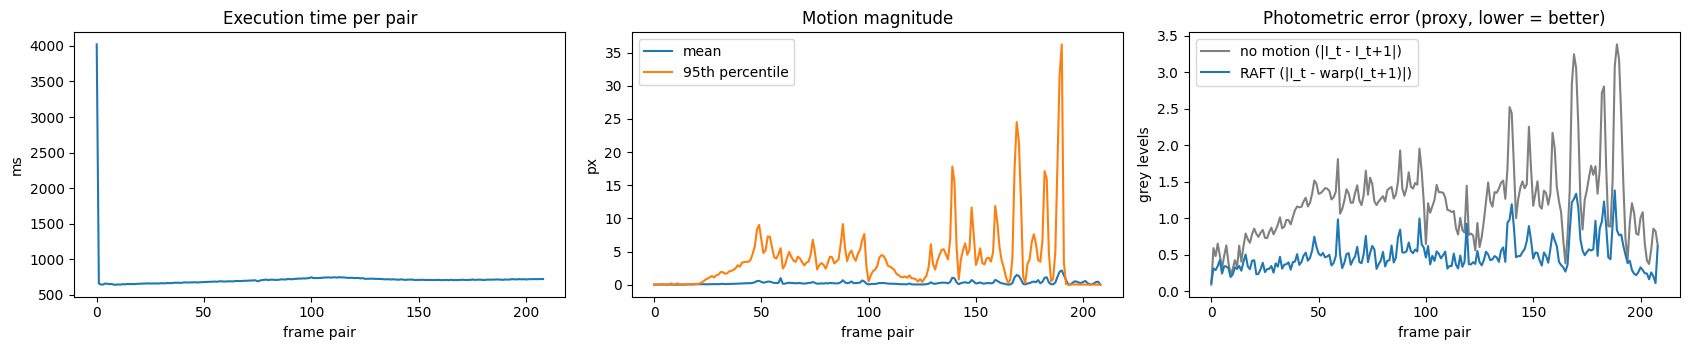

         pair  time_ms  mean_mag  p95_mag  photo_err  photo_zero_flow  temporal_var
count  209.00   209.00    209.00   209.00     209.00           209.00        208.00
mean   104.00   719.91      0.29     3.89       0.50             1.22          0.10
std     60.48   231.13      0.31     4.91       0.22             0.55          0.11
min      0.00   644.06      0.01     0.02       0.11             0.09          0.01
25%     52.00   685.54      0.09     0.92       0.36             0.84          0.03
50%    104.00   712.13      0.23     3.14       0.46             1.23          0.05
75%    156.00   721.53      0.33     4.70       0.56             1.41          0.11
max    208.00  4021.73      2.16    36.26       1.38             3.38          0.53


In [13]:
rows = []
for ti in range(n_pairs):
    f = flows[ti].astype(np.float32)
    mag = np.linalg.norm(f, axis=0)
    pe, base = photometric_error(VIDEO_FRAMES[ti], VIDEO_FRAMES[ti + 1], f)
    tv = float(np.abs(f - flows[ti - 1].astype(np.float32)).mean()) if ti > 0 else np.nan
    rows.append(dict(pair=ti, time_ms=times_ms[ti], mean_mag=float(mag.mean()), p95_mag=float(np.percentile(mag, 95)),
                     photo_err=pe, photo_zero_flow=base, temporal_var=tv))
import pandas as pd
per_pair = pd.DataFrame(rows)
per_pair.to_csv(f"{OUT}/per_pair.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
ax[0].plot(per_pair.time_ms); ax[0].set_title("Execution time per pair"); ax[0].set_xlabel("frame pair"); ax[0].set_ylabel("ms")
ax[1].plot(per_pair.mean_mag, label="mean"); ax[1].plot(per_pair.p95_mag, label="95th percentile")
ax[1].set_title("Motion magnitude"); ax[1].set_xlabel("frame pair"); ax[1].set_ylabel("px"); ax[1].legend()
ax[2].plot(per_pair.photo_zero_flow, label="no motion (|I_t - I_t+1|)", color="grey")
ax[2].plot(per_pair.photo_err, label="RAFT (|I_t - warp(I_t+1)|)")
ax[2].set_title("Photometric error (proxy, lower = better)"); ax[2].set_xlabel("frame pair"); ax[2].set_ylabel("grey levels"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/per_pair_stats.png", dpi=130); plt.show()
print(per_pair.describe().round(2).to_string())

## 7. Visualisations : vidéo, flux en couleur, cartes de magnitude, champ de vecteurs
Teinte = **direction**, saturation = **magnitude**, blanc = pas de mouvement (chaque image de flux est normalisée par son propre maximum).

In [14]:
COMBO = f"{WORK}/combo"
shutil.rmtree(COMBO, ignore_errors=True); os.makedirs(COMBO)
for ti in range(n_pairs):
    a = cv2.imread(frame_files[ti]); b = cv2.imread(f"{FLOW_PNG}/{ti:05d}.png")
    cv2.putText(a, f"Input  t={ti}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(b, f"RAFT ({RAFT_MODEL})", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2, cv2.LINE_AA)
    cv2.imwrite(f"{COMBO}/{ti:05d}.jpg", cv2.hconcat([a, b]))
RESULT_VIDEO = f"{OUT}/raft_result.mp4"
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", str(FPS), "-i", f"{COMBO}/%05d.jpg",
                "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2", "-c:v", "libx264", "-pix_fmt", "yuv420p", RESULT_VIDEO], check=True)
from IPython.display import HTML, display
from base64 import b64encode
if os.path.getsize(RESULT_VIDEO) < 40e6:
    display(HTML(f'<video width="100%" controls loop autoplay muted src="data:video/mp4;base64,{b64encode(open(RESULT_VIDEO, "rb").read()).decode()}"></video>'))

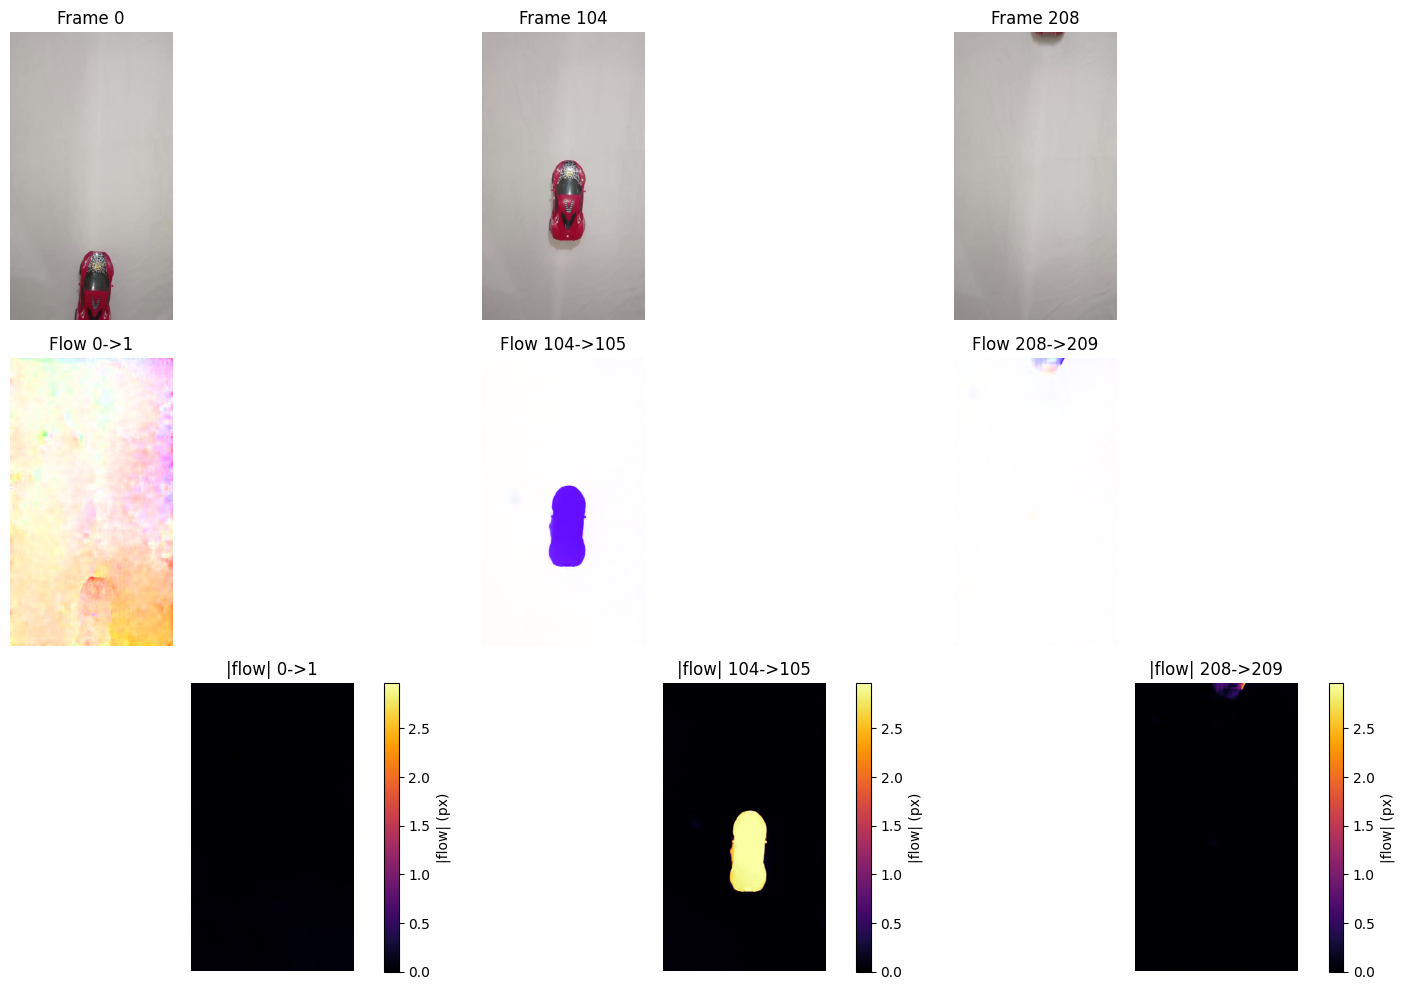

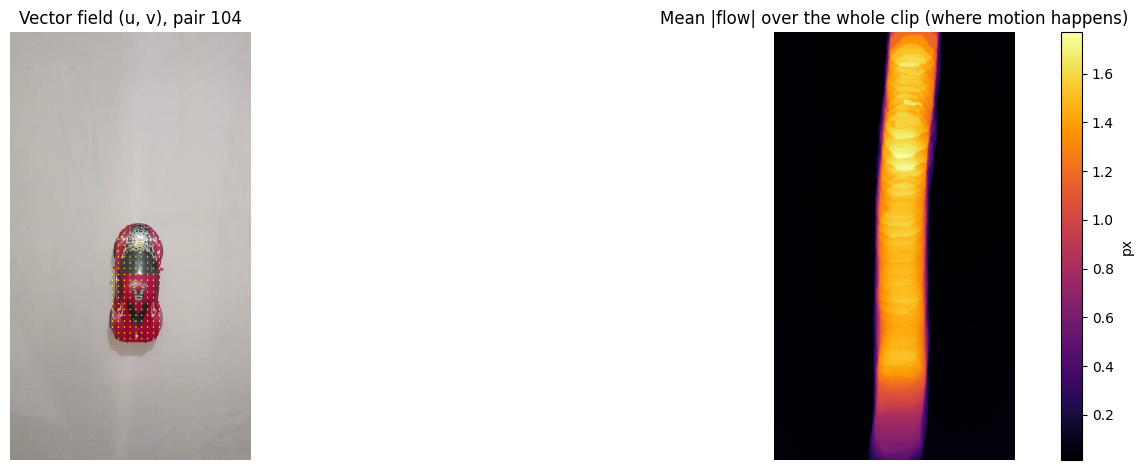

In [15]:
idx = sorted(set([0, ATT_PAIR, n_pairs - 1]))
vmax = float(np.percentile(np.linalg.norm(flows[idx].astype(np.float32), axis=1), 99.5))
fig, axes = plt.subplots(3, len(idx), figsize=(5.5 * len(idx), 10), squeeze=False)
for j, i in enumerate(idx):
    f = flows[i].astype(np.float32)
    axes[0, j].imshow(VIDEO_FRAMES[i]); axes[0, j].set_title(f"Frame {i}"); axes[0, j].axis("off")
    axes[1, j].imshow(flow_viz.flow_to_image(f.transpose(1, 2, 0))); axes[1, j].set_title(f"Flow {i}->{i+1}"); axes[1, j].axis("off")
    magnitude_heatmap(axes[2, j], f, f"|flow| {i}->{i+1}", vmax=vmax)
plt.tight_layout(); plt.savefig(f"{FIG}/frames_flow_heatmaps.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
f = flows[ATT_PAIR].astype(np.float32)
quiver_overlay(ax[0], VIDEO_FRAMES[ATT_PAIR], f, step=max(8, W0 // 40), title=f"Vector field (u, v), pair {ATT_PAIR}")
mean_mag_map = np.linalg.norm(flows.astype(np.float32), axis=1).mean(0)
im = ax[1].imshow(mean_mag_map, cmap="inferno"); ax[1].axis("off"); ax[1].set_title("Mean |flow| over the whole clip (where motion happens)")
plt.colorbar(im, ax=ax[1], fraction=0.03, label="px")
plt.tight_layout(); plt.savefig(f"{FIG}/vectors_and_motion_energy.png", dpi=130); plt.show()

## 8. Le volume de corrélation (la « matrice » de RAFT)
Pour chaque pixel $(i,j)$ de l'image 1 et chaque pixel $(k,l)$ de l'image 2 (à la résolution 1/8) :
$C_{ijkl}=\frac{1}{\sqrt D}\langle g(I_1)_{ij},\, g(I_2)_{kl}\rangle$ — un tenseur 4D de taille $H/8\times W/8\times H/8\times W/8$.
Pour un pixel requête ★ de l'image 1, la tranche $C_{ij\,\cdot\,\cdot}$ est une carte 2D sur l'image 2 : un pic lumineux = l'endroit où ce pixel est probablement allé.
La pyramide moyenne les deux dernières dimensions (noyaux 1, 2, 4, 8) pour capter les grands déplacements ; le GRU ne lit qu'une
fenêtre $(2r+1)\times(2r+1)=9\times9$ ($r=4$) autour de l'estimation courante à chaque niveau.

**Résultat :** volume de 128×72×128×72 = 84,9 M valeurs (324 Mo en float32). Sa taille croît comme le carré du nombre de pixels.

feature maps: (1, 256, 128, 72) -> correlation volume 128x72x128x72 = 84.9 M values (324 MB in float32): grows as (number of pixels)^2


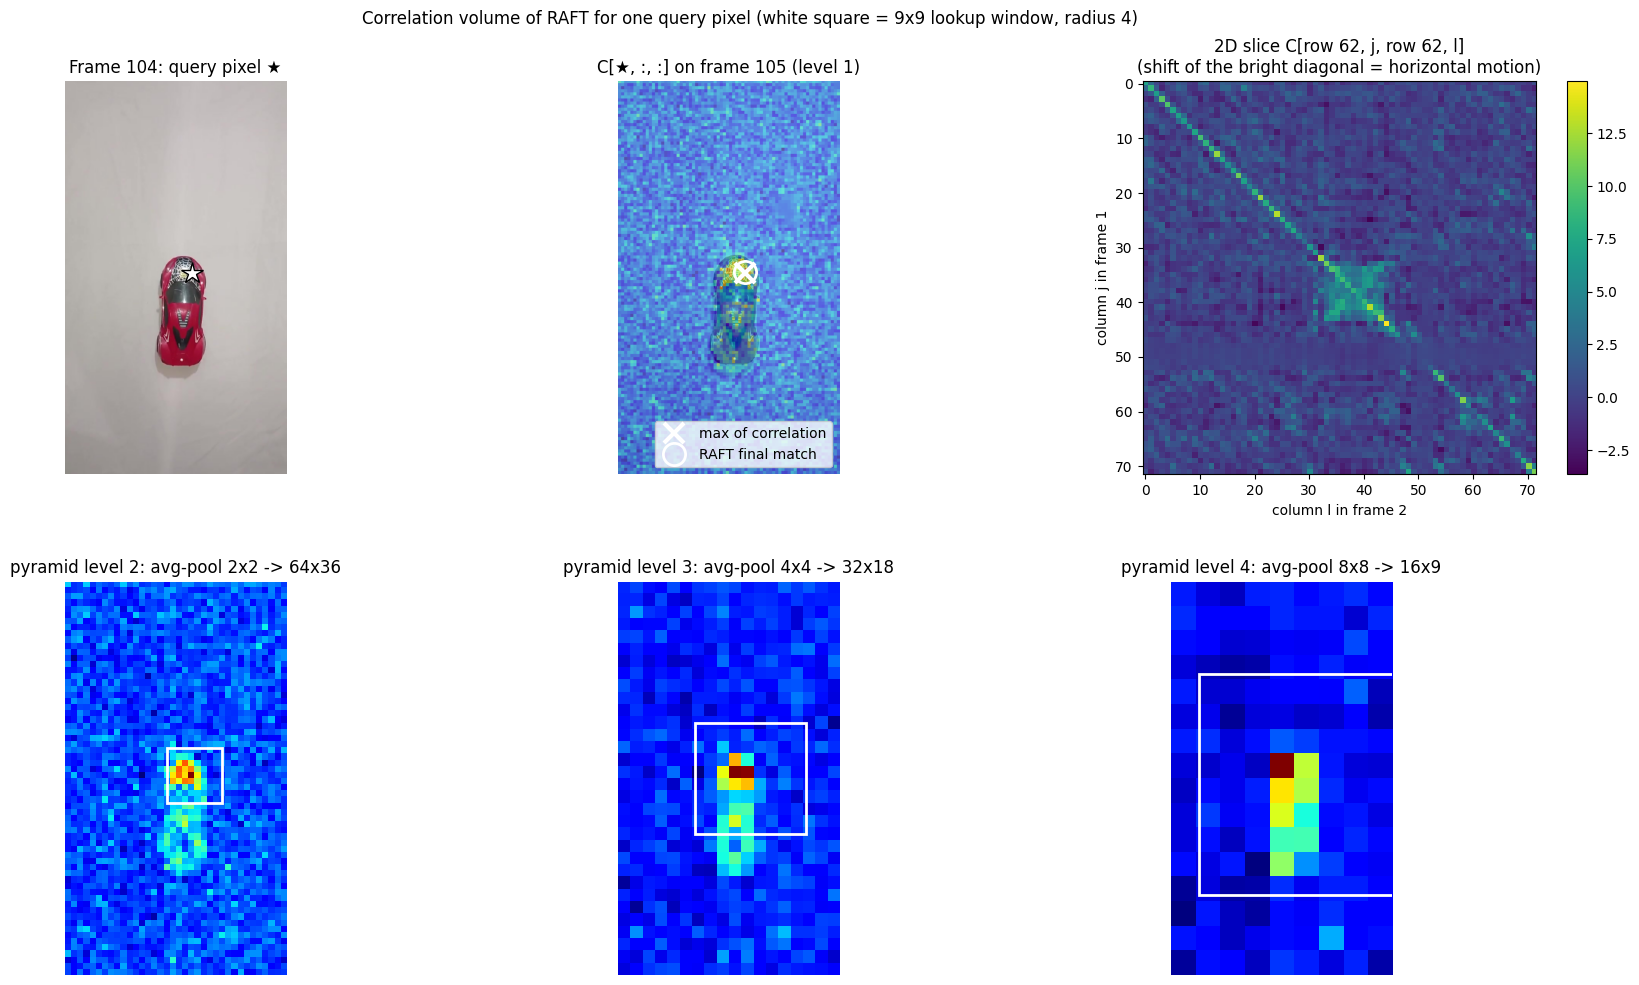

In [16]:
a_img, b_img = VIDEO_FRAMES[ATT_PAIR], VIDEO_FRAMES[ATT_PAIR + 1]
i1, i2 = padder.pad(to_t(a_img), to_t(b_img))
with torch.no_grad():
    fmap1, fmap2 = model.fnet([2 * (i1 / 255.0) - 1.0, 2 * (i2 / 255.0) - 1.0])
    corr = CorrBlock.corr(fmap1.float(), fmap2.float())[0, :, :, 0]      # (h8, w8, h8, w8)
h8, w8 = corr.shape[:2]
pad_l, pad_t = padder._pad[0], padder._pad[2]
D = fmap1.shape[1]
print(f"feature maps: {tuple(fmap1.shape)} -> correlation volume {h8}x{w8}x{h8}x{w8} = {corr.numel()/1e6:.1f} M values "
      f"({corr.numel()*4/2**20:.0f} MB in float32): grows as (number of pixels)^2")

f = flows[ATT_PAIR].astype(np.float32)
if QUERY_XY is None:
    mag = np.linalg.norm(f, axis=0)
    yq, xq = np.unravel_index(np.argmin(np.abs(mag - np.percentile(mag, 98))), mag.shape)
else:
    xq, yq = QUERY_XY
qi, qj = (yq + pad_t) // 8, (xq + pad_l) // 8
cmap_q = corr[qi, qj].cpu()
xt, yt = xq + f[0, yq, xq], yq + f[1, yq, xq]                              # position d'arrivée du pixel selon RAFT

def up8(m):
    m = cv2.resize(np.asarray(m, np.float32), (w8 * 8, h8 * 8), interpolation=cv2.INTER_NEAREST)
    return m[pad_t:pad_t + H0, pad_l:pad_l + W0]

pyr = [cmap_q[None, None]]
for _ in range(3):
    pyr.append(torch.nn.functional.avg_pool2d(pyr[-1], 2, stride=2))
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes[0, 0].imshow(a_img); axes[0, 0].plot(xq, yq, "w*", ms=16, mec="k"); axes[0, 0].set_title(f"Frame {ATT_PAIR}: query pixel ★"); axes[0, 0].axis("off")
pk = np.unravel_index(int(cmap_q.argmax()), cmap_q.shape)
axes[0, 1].imshow(b_img); axes[0, 1].imshow(up8(cmap_q.numpy()), cmap="jet", alpha=0.55)
axes[0, 1].plot(pk[1] * 8 - pad_l + 4, pk[0] * 8 - pad_t + 4, "wx", ms=14, mew=3, label="max of correlation")
axes[0, 1].plot(xt, yt, "o", mfc="none", mec="w", ms=16, mew=2, label="RAFT final match")
axes[0, 1].legend(loc="lower right"); axes[0, 1].set_title(f"C[★, :, :] on frame {ATT_PAIR+1} (level 1)"); axes[0, 1].axis("off")
row = corr[qi, :, qi, :].cpu().numpy()
im = axes[0, 2].imshow(row, cmap="viridis"); axes[0, 2].set_xlabel("column l in frame 2"); axes[0, 2].set_ylabel("column j in frame 1")
axes[0, 2].set_title(f"2D slice C[row {qi}, j, row {qi}, l]\n(shift of the bright diagonal = horizontal motion)"); plt.colorbar(im, ax=axes[0, 2], fraction=0.04)
for k, ax in zip([1, 2, 3], axes[1]):
    lvl = pyr[k][0, 0].numpy()
    ax.imshow(lvl, cmap="jet"); ax.set_title(f"pyramid level {k+1}: avg-pool {2**k}x{2**k} -> {lvl.shape[0]}x{lvl.shape[1]}")
    cx, cy = (xt + pad_l) / 8 / 2**k, (yt + pad_t) / 8 / 2**k
    ax.add_patch(plt.Rectangle((cx - 4.5, cy - 4.5), 9, 9, fill=False, ec="w", lw=2)); ax.axis("off")
plt.suptitle("Correlation volume of RAFT for one query pixel (white square = 9x9 lookup window, radius 4)")
plt.tight_layout(h_pad=3); plt.savefig(f"{FIG}/correlation_volume.png", dpi=130); plt.show()

## 9. Itérations du GRU
Équations de mise à jour (article, Éq. 3–6), avec $x_t$ = [caractéristiques de corrélation, caractéristiques du flux, contexte] :
$z_t=\sigma(\mathrm{Conv}_{3\times3}([h_{t-1},x_t],W_z))$, $r_t=\sigma(\mathrm{Conv}_{3\times3}([h_{t-1},x_t],W_r))$,
$\tilde h_t=\tanh(\mathrm{Conv}_{3\times3}([r_t\odot h_{t-1},x_t],W_h))$, $h_t=(1-z_t)\odot h_{t-1}+z_t\odot\tilde h_t$,
puis deux convolutions prédisent $\Delta f$ et $f_{k+1}=f_k+\Delta f$.

La deuxième cellule compare la vitesse et la qualité pour différents nombres d'itérations et pour RAFT-small (sur 40 paires).

**Résultat :** l'erreur photométrique se stabilise dès 5 itérations (0,33) alors que le temps augmente linéairement
(230 ms à 2 itérations, 713 ms à 20, 1050 ms à 32). RAFT-small (0,99 M paramètres) est environ 3× plus rapide mais moins précis (0,41).

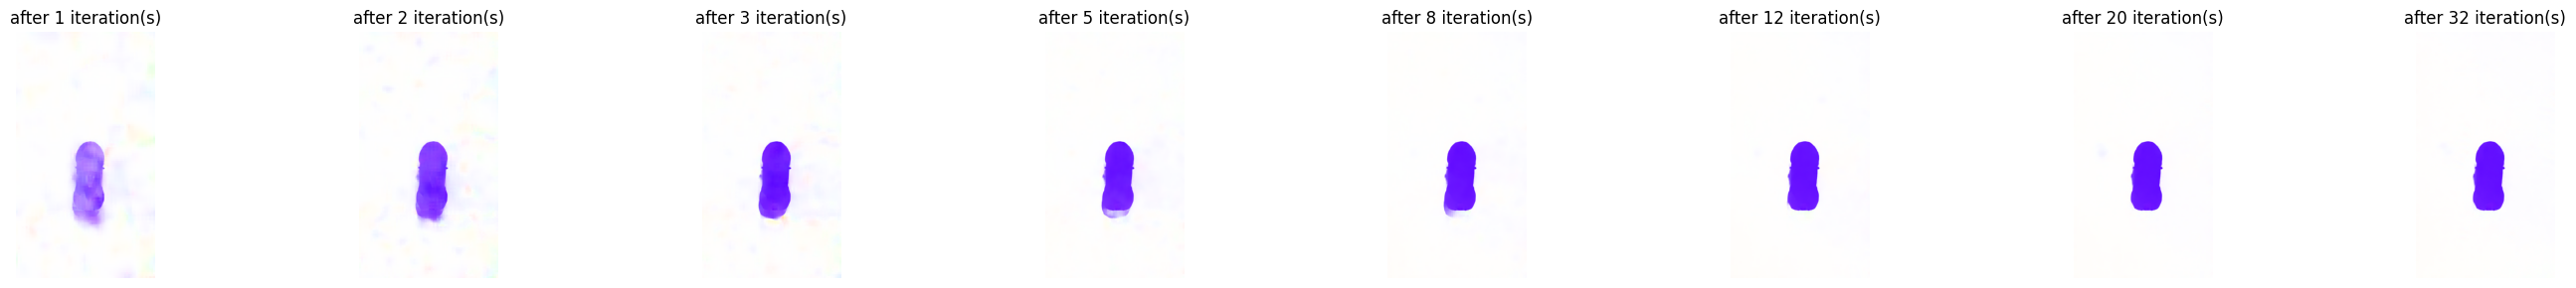

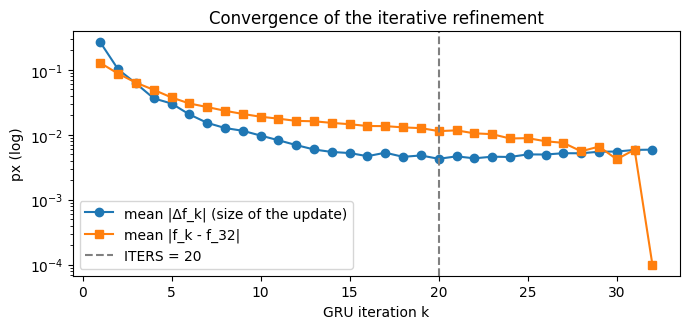

In [17]:
with torch.no_grad():
    preds = model(i1, i2, iters=max(ITERS, 32), test_mode=False)        # liste : flux après chaque itération
per_iter = [padder.unpad(p[0]).cpu().numpy() for p in preds]
show = [k for k in [1, 2, 3, 5, 8, 12, ITERS, 32] if k <= len(per_iter)]
show = sorted(set(show))
fig, axes = plt.subplots(1, len(show), figsize=(3.6 * len(show), 3))
for ax, k in zip(axes, show):
    ax.imshow(flow_viz.flow_to_image(per_iter[k - 1].transpose(1, 2, 0))); ax.set_title(f"after {k} iteration(s)"); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/iterations_flow.png", dpi=130); plt.show()

final = per_iter[-1]
update_size = [float(np.linalg.norm(per_iter[0], axis=0).mean())] + \
              [float(np.linalg.norm(per_iter[k] - per_iter[k - 1], axis=0).mean()) for k in range(1, len(per_iter))]
dist_to_final = [float(np.linalg.norm(p - final, axis=0).mean()) for p in per_iter]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(range(1, len(per_iter) + 1), update_size, "o-", label="mean |Δf_k| (size of the update)")
ax.semilogy(range(1, len(per_iter) + 1), np.maximum(dist_to_final, 1e-4), "s-", label="mean |f_k - f_32|")
ax.axvline(ITERS, color="grey", ls="--", label=f"ITERS = {ITERS}")
ax.set_xlabel("GRU iteration k"); ax.set_ylabel("px (log)"); ax.legend(); ax.set_title("Convergence of the iterative refinement")
plt.tight_layout(); plt.savefig(f"{FIG}/iterations_convergence.png", dpi=130); plt.show()

raft-small: 0.99 M parameters
      model  iters  ms_per_pair  fps  photo_err  mean_diff_vs_default_px  peak_mem_MB
raft-sintel      2       230.66 4.34       0.35                     0.04      1230.06
raft-sintel      5       325.68 3.07       0.33                     0.02      1230.20
raft-sintel      8       406.37 2.46       0.33                     0.01      1230.06
raft-sintel     12       499.84 2.00       0.33                     0.01      1230.49
raft-sintel     20       712.74 1.40       0.33                     0.00      1230.20
raft-sintel     32      1049.79 0.95       0.33                     0.01      1282.07
 raft-small     12       163.87 6.10       0.41                     0.11      1221.06
 raft-small     20       243.10 4.11       0.41                     0.11      1221.06


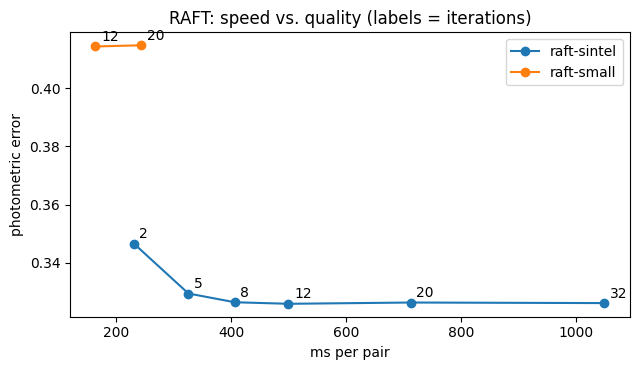

In [ ]:
RUN_ITER_STUDY = True
STUDY_PAIRS = 40
iter_study = []
if RUN_ITER_STUDY:
    n_s = min(STUDY_PAIRS, n_pairs)
    variants = [(RAFT_MODEL, model, it) for it in [2, 5, 8, 12, 20, 32]]
    if RAFT_MODEL != "raft-small":
        small = load_raft("raft-small")
        print(f"raft-small: {sum(p.numel() for p in small.parameters())/1e6:.2f} M parameters")
        variants += [("raft-small", small, it) for it in [12, 20]]
    for name, net, it in variants:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        fl, tms = run_sequence(VIDEO_FRAMES, net=net, iters=it, warm_start=False, n_pairs=n_s)
        pe = np.mean([photometric_error(VIDEO_FRAMES[i], VIDEO_FRAMES[i + 1], fl[i].astype(np.float32))[0] for i in range(n_s)])
        diff = np.mean([np.linalg.norm(fl[i].astype(np.float32) - flows[i].astype(np.float32), axis=0).mean() for i in range(n_s)])
        iter_study.append(dict(model=name, iters=it, ms_per_pair=float(tms[WARMUP:].mean()), fps=float(1000 / tms[WARMUP:].mean()),
                               photo_err=float(pe), mean_diff_vs_default_px=float(diff),
                               peak_mem_MB=torch.cuda.max_memory_allocated() / 2**20))
    iter_study = pd.DataFrame(iter_study); print(iter_study.round(2).to_string(index=False))
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for name, g in iter_study.groupby("model"):
        ax.plot(g.ms_per_pair, g.photo_err, "o-", label=name)
        for _, r in g.iterrows():
            ax.annotate(f"{int(r.iters)}", (r.ms_per_pair, r.photo_err), textcoords="offset points", xytext=(4, 4))
    ax.set_xlabel("ms per pair"); ax.set_ylabel("photometric error"); ax.legend(); ax.set_title("RAFT: speed vs. quality (labels = iterations)")
    plt.tight_layout(); plt.savefig(f"{FIG}/iterations_speed_quality.png", dpi=130); plt.show()

## 10. Ablation sur notre vidéo : deux images vs. warm-start
RAFT n'a pas de mémoire, mais l'article propose un **warm-start** pour les vidéos : le flux de la paire précédente est projeté vers l'avant et sert d'initialisation $f_0$.
C'est l'équivalent le plus proche, pour RAFT, de la mémoire temporelle de MemFlow.

**Résultat (80 paires) :** pas de gain mesurable (erreur photométrique 0,407 vs 0,415, écart moyen entre les deux flux 0,06 px).

In [ ]:
RUN_WARMSTART_ABLATION = True   
ablation = {}
if RUN_WARMSTART_ABLATION:
    n_s = min(STUDY_PAIRS * 2, n_pairs)
    fl_a, t_a = run_sequence(VIDEO_FRAMES, warm_start=False, n_pairs=n_s)
    fl_b, t_b = run_sequence(VIDEO_FRAMES, warm_start=True, n_pairs=n_s)
    def summarise(fl, tms):
        fl = [x.astype(np.float32) for x in fl]
        pe = np.mean([photometric_error(VIDEO_FRAMES[i], VIDEO_FRAMES[i + 1], fl[i])[0] for i in range(n_s)])
        tv = np.mean([np.abs(fl[i] - fl[i - 1]).mean() for i in range(1, n_s)])
        return dict(photo_err=float(pe), temporal_var=float(tv), ms_per_pair=float(np.mean(tms[WARMUP:])))
    ablation = {"two_frame": summarise(fl_a, t_a), "warm_start": summarise(fl_b, t_b)}
    ablation["mean_diff_px"] = float(np.mean([np.linalg.norm(fl_a[i].astype(np.float32) - fl_b[i].astype(np.float32), axis=0).mean() for i in range(n_s)]))
    print(pd.DataFrame({k: v for k, v in ablation.items() if isinstance(v, dict)}).round(3).to_string())
    print(f"mean |flow_two_frame - flow_warm_start| = {ablation['mean_diff_px']:.3f} px over {n_s} pairs")

              two_frame  warm_start
photo_err         0.407       0.415
temporal_var      0.048       0.046
ms_per_pair     720.050     735.627
mean |flow_two_frame - flow_warm_start| = 0.061 px over 80 pairs


## 11. Précision avec vérité terrain : benchmark Middlebury
Même protocole que dans le notebook MemFlow : 8 séquences avec vérité terrain pour frame10 → frame11.
- **EPE** $=\frac1N\sum_p\|f_{pred}(p)-f_{gt}(p)\|_2$ (pixels) — **Fl-all** = % de pixels avec EPE > 3 px et > 5 % de $\|f_{gt}\|$.
- Deux images = seulement frame10/frame11. Warm-start = la séquence est traitée à partir de frame07.

**Résultat :** EPE moyen 0,282 px (Fl-all 0,94 %) en deux images, 0,285 px avec warm-start.

               epe  fl_all  epe_warm_start  fl_all_warm_start  n_history_frames
Dimetrodon   0.163   0.000           0.163              0.000              0.00
Grove2       0.212   0.408           0.213              0.389              3.00
Grove3       0.633   4.515           0.614              4.466              3.00
Hydrangea    0.216   0.393           0.238              0.405              3.00
RubberWhale  0.177   0.045           0.196              0.051              3.00
Urban2       0.293   0.601           0.284              0.618              3.00
Urban3       0.300   1.427           0.308              1.271              3.00
Venus        0.261   0.107           0.261              0.107              0.00
mean         0.282   0.937           0.285              0.913              2.25


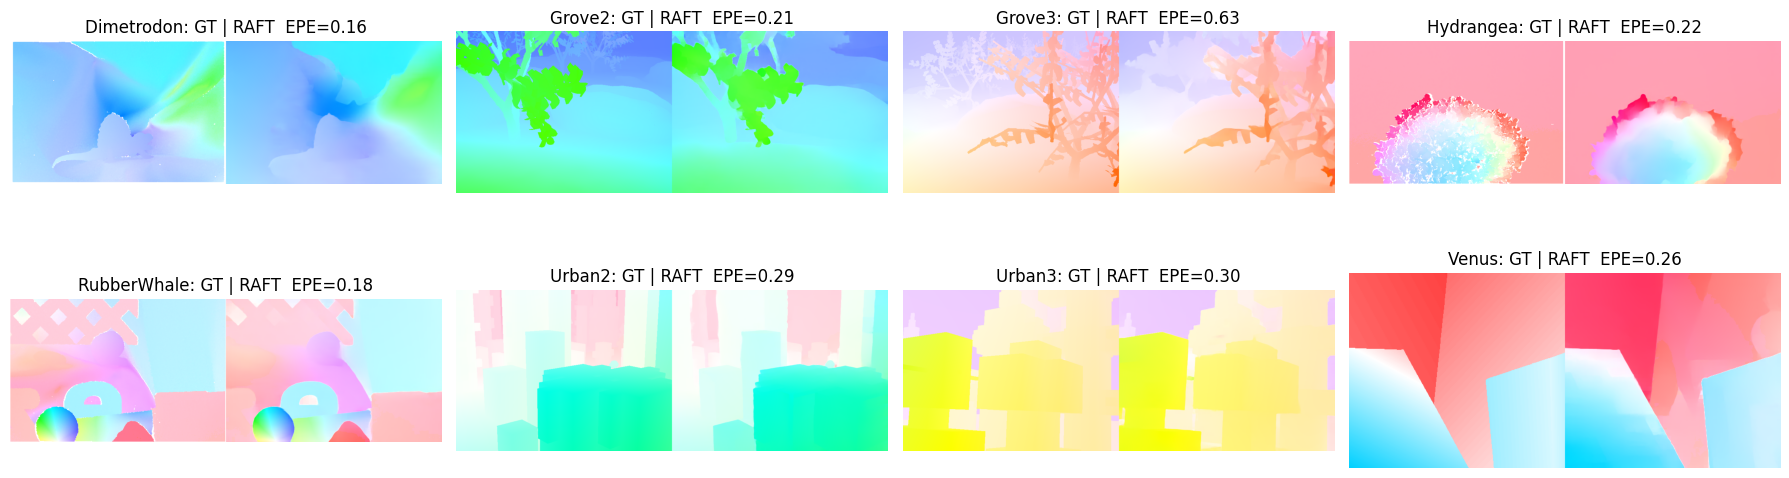

In [ ]:
RUN_MIDDLEBURY = True
middlebury = {}
if RUN_MIDDLEBURY:
    seqs = get_middlebury()
    for name, s in seqs.items():
        imgs = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in s["frames"]]
        fl2, _ = run_sequence(imgs[-2:], warm_start=False)
        flw, _ = run_sequence(imgs, warm_start=True)
        e2, f2 = flow_metrics(fl2[-1].astype(np.float32).transpose(1, 2, 0), s["gt"])
        ew, fw = flow_metrics(flw[-1].astype(np.float32).transpose(1, 2, 0), s["gt"])
        middlebury[name] = dict(epe=e2, fl_all=f2, epe_warm_start=ew, fl_all_warm_start=fw,
                                n_history_frames=len(imgs) - 2, last_pred=fl2[-1])
    mb = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "last_pred"} for k, v in middlebury.items()}).T
    mb.loc["mean"] = mb.mean()
    print(mb.round(3).to_string())
    fig, axes = plt.subplots(2, 4, figsize=(18, 6))
    for ax, (name, s) in zip(axes.ravel(), seqs.items()):
        gt = s["gt"].copy(); gt[np.abs(gt) > 1e9] = 0
        ax.imshow(np.hstack([flow_viz.flow_to_image(gt), flow_viz.flow_to_image(middlebury[name]["last_pred"].astype(np.float32).transpose(1, 2, 0))]))
        ax.set_title(f"{name}: GT | RAFT  EPE={middlebury[name]['epe']:.2f}"); ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{FIG}/middlebury.png", dpi=110); plt.show()

## 12. Sauvegarde du résumé
Tous les résultats numériques sont regroupés dans `results.json` (dossier `flow_optique/raft` du Drive).

In [21]:
summary = dict(
    model="RAFT", variant=RAFT_MODEL, checkpoint=f"{RAFT_MODEL}.pth", iters=ITERS, warm_start=WARM_START, gpu=GPU_NAME,
    n_params=N_PARAMS, clip=CLIP_INFO, load_time_s=LOAD_TIME_S, total_time_s=TOTAL_TIME_S,
    time_ms_per_pair_mean=float(steady.mean()), time_ms_per_pair_median=float(np.median(steady)),
    time_ms_first_pair=float(times_ms[0]), pairs_per_s=float(1000 / steady.mean()),
    peak_mem_alloc_MB=PEAK_ALLOC_MB, peak_mem_reserved_MB=PEAK_RESERVED_MB,
    corr_volume_MB=float(corr.numel() * 4 / 2**20),
    mean_flow_magnitude_px=float(per_pair.mean_mag.mean()), max_flow_magnitude_px=float(per_pair.p95_mag.max()),
    photometric_error_mean=float(per_pair.photo_err.mean()), photometric_zero_flow_mean=float(per_pair.photo_zero_flow.mean()),
    temporal_var_mean=float(per_pair.temporal_var.mean()), att_pair=int(ATT_PAIR),
    iter_study=iter_study.to_dict("records") if len(iter_study) else [],
    warm_start_ablation=ablation,
    middlebury={k: {kk: vv for kk, vv in v.items() if kk != "last_pred"} for k, v in middlebury.items()},
)
json.dump(summary, open(f"{OUT}/results.json", "w"), indent=1)
print(json.dumps({k: v for k, v in summary.items() if k not in ("iter_study", "middlebury", "clip")}, indent=1))

{
 "model": "RAFT",
 "variant": "raft-sintel",
 "checkpoint": "raft-sintel.pth",
 "iters": 20,
 "warm_start": false,
 "gpu": "Tesla T4",
 "n_params": 5257536,
 "load_time_s": 0.34163675299998886,
 "total_time_s": 168.13145378000002,
 "time_ms_per_pair_mean": 704.5275801553456,
 "time_ms_per_pair_median": 712.1481425000411,
 "time_ms_first_pair": 4021.7274729999417,
 "pairs_per_s": 1.4193908488004172,
 "peak_mem_alloc_MB": 725.9228515625,
 "peak_mem_reserved_MB": 1086.0,
 "corr_volume_MB": 324.0,
 "mean_flow_magnitude_px": 0.2927675470442435,
 "max_flow_magnitude_px": 36.25617980957031,
 "photometric_error_mean": 0.49752419260129976,
 "photometric_zero_flow_mean": 1.2234000591784002,
 "temporal_var_mean": 0.09587959756026976,
 "att_pair": 104,
 "warm_start_ablation": {
  "two_frame": {
   "photo_err": 0.4070386766456068,
   "temporal_var": 0.04843591898679733,
   "ms_per_pair": 720.0503444545435
  },
  "warm_start": {
   "photo_err": 0.41527845626696946,
   "temporal_var": 0.04615803062

## 13. Conclusion et interprétation générale

**Qualité du flux.** Sur notre vidéo, RAFT (`raft-sintel`, 20 itérations) explique bien le mouvement : l'erreur photométrique moyenne
passe de 1,22 (sans flux) à 0,50 avec le flux estimé, soit environ 60 % de réduction. Sur Middlebury, où la vérité terrain est disponible,
l'EPE moyen est de 0,28 px et seulement 0,94 % des pixels sont en erreur (Fl-all) : le modèle pré-entraîné généralise bien sans ré-entraînement.

**Coût de calcul.** Cette précision a un prix : 704 ms par paire en 576×1024 sur un GPU T4 (≈ 1,4 paire/s), donc environ 168 s pour un clip de 7 s,
très loin du temps réel. La cause principale est le volume de corrélation complet (324 Mo ici), dont la taille croît comme le carré du nombre
de pixels : c'est la force de RAFT (toutes les correspondances possibles) mais aussi sa principale limite pour les hautes résolutions.

**Compromis vitesse / qualité.** Le raffinement itératif par le GRU converge vite sur notre vidéo : dès 5 à 8 itérations l'erreur photométrique
est la même qu'à 20 ou 32 itérations, pour un temps environ 2 fois plus faible. RAFT-small est 3 à 4 fois plus rapide mais nettement moins précis
(0,41 contre 0,33). Le nombre d'itérations est donc le réglage le plus simple pour adapter RAFT à un budget de temps.

**Information temporelle.** Le warm-start n'apporte aucun gain mesurable, ni sur notre vidéo (0,407 vs 0,415, écart de 0,06 px entre les flux)
ni sur Middlebury (EPE 0,282 vs 0,285). RAFT reste fondamentalement une méthode à deux images : il n'exploite pas réellement l'historique
de la vidéo, ce qui motive l'étude de MemFlow et de sa mémoire temporelle.

**Limites de l'étude.** Le mouvement de notre vidéo est globalement faible (0,29 px en moyenne, 95e percentile de 3,9 px) : c'est un cas
plutôt favorable, et l'intérêt de plus d'itérations ou du warm-start serait sans doute plus visible avec de grands déplacements.
L'erreur photométrique n'est qu'un indicateur (sensible aux changements d'éclairage et aux occultations), et les temps dépendent du GPU utilisé.